In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [2]:
candidate_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal", "target"
]

categorical_columns = [
    col for col in candidate_columns if col in df.columns
]

print("Categorical columns:", categorical_columns)

Categorical columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']


In [3]:
def manual_category_counts(series):
    counts = {}

    for value in series:
        if pd.isna(value):
            category = "Missing"
        else:
            category = str(value)

        if category not in counts:
            counts[category] = 0

        counts[category] += 1

    return counts


for col in categorical_columns:
    print(f"\n{col}:")
    print(manual_category_counts(df[col]))


sex:
{'1': 713, '0': 312}

cp:
{'0': 497, '1': 167, '2': 284, '3': 77}

fbs:
{'0': 872, '1': 153}

restecg:
{'1': 513, '0': 497, '2': 15}

exang:
{'0': 680, '1': 345}

slope:
{'2': 469, '0': 74, '1': 482}

ca:
{'2': 134, '0': 578, '1': 226, '3': 69, '4': 18}

thal:
{'3': 410, '2': 544, '1': 64, '0': 7}

target:
{'0': 499, '1': 526}


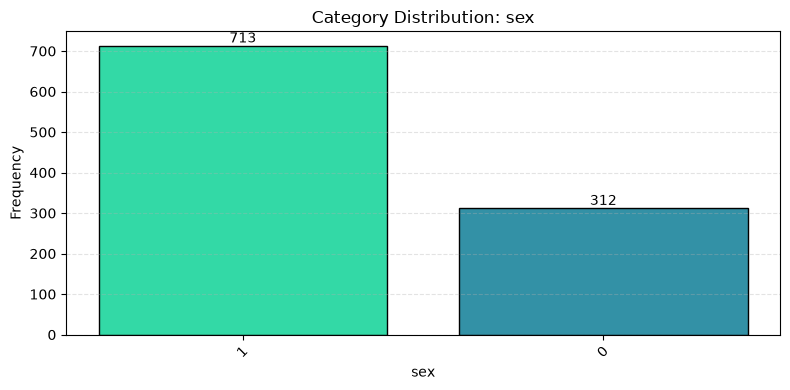

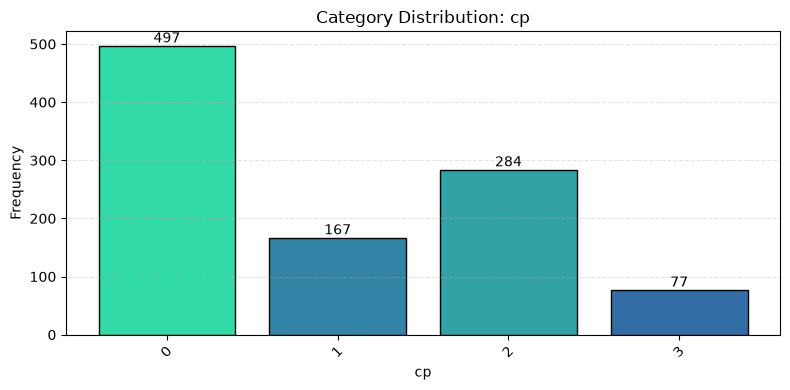

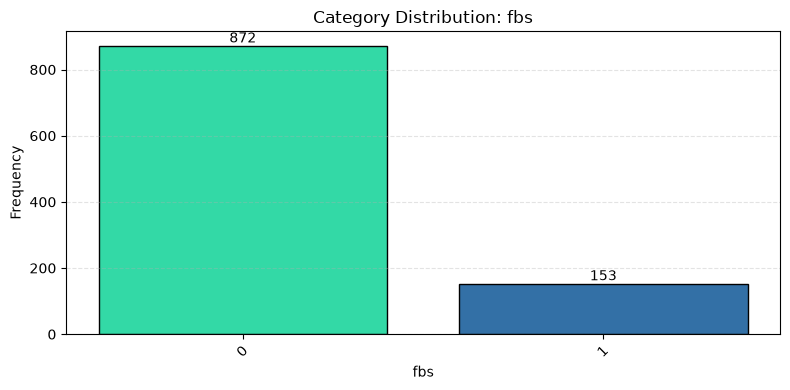

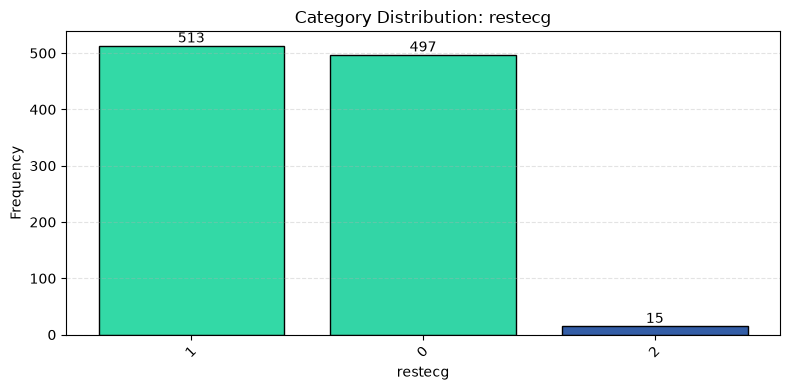

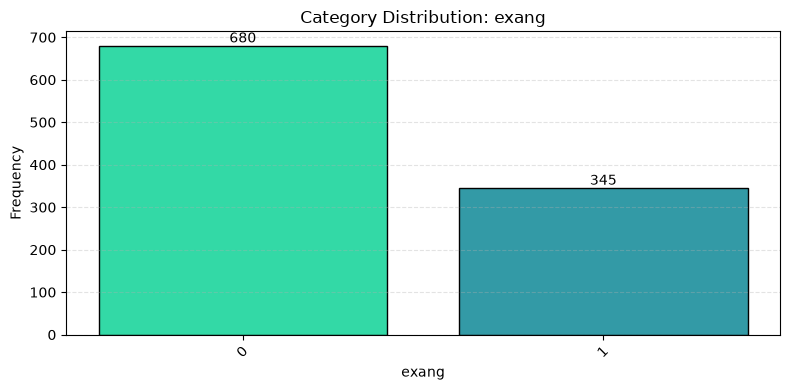

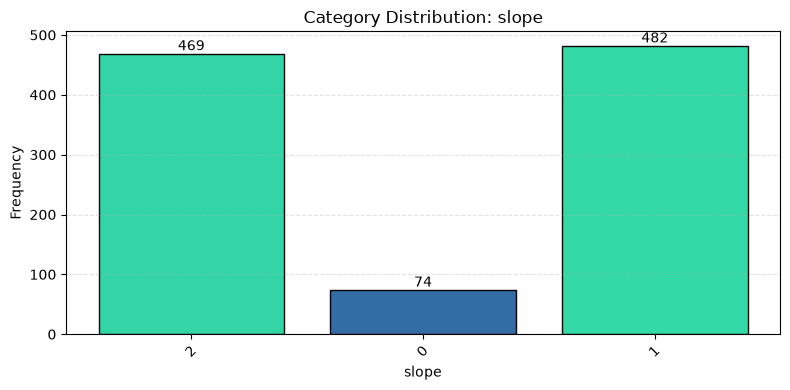

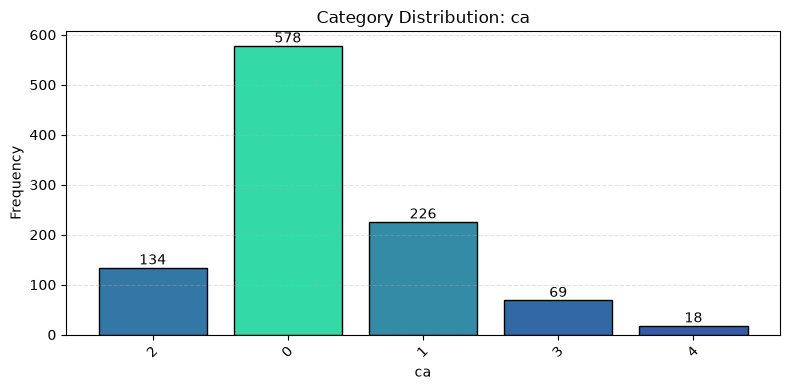

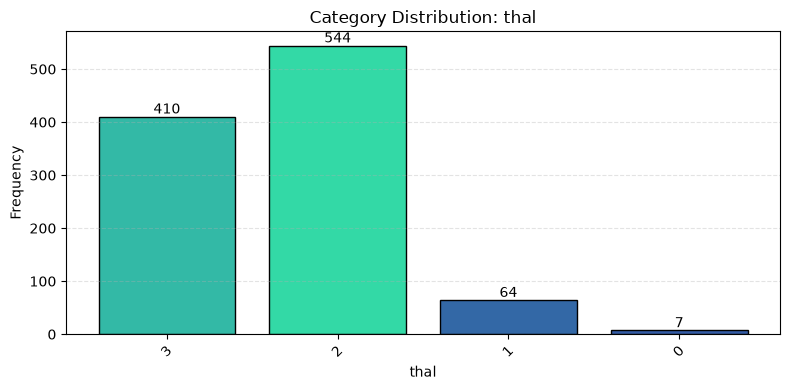

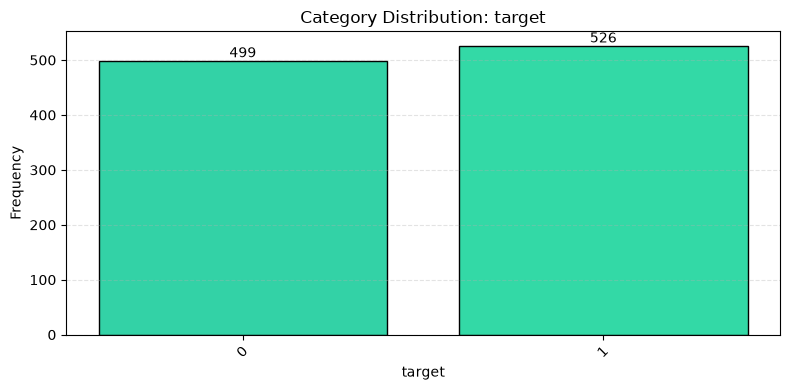

In [4]:
for col in categorical_columns:
    counts = manual_category_counts(df[col])

    categories = list(counts.keys())
    frequencies = list(counts.values())

    if not categories:
        continue

    positions = list(range(len(categories)))

    # Adjust bar width according to category count
    bar_width = max(0.35, min(0.8, 5 / len(categories)))

    # Generate colors dynamically from frequencies
    max_frequency = max(frequencies) if frequencies else 1

    colors = [
        (0.2, 0.35 + 0.5 * (frequency / max_frequency), 0.65)
        for frequency in frequencies
    ]

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        positions,
        frequencies,
        width=bar_width,
        color=colors,
        edgecolor="black"
    )

    ax.set_title(f"Category Distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.set_xticks(positions)
    ax.set_xticklabels(categories, rotation=45)

    for position, frequency in zip(positions, frequencies):
        ax.text(
            position,
            frequency,
            str(frequency),
            ha="center",
            va="bottom"
        )

    ax.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

In [5]:
for col in categorical_columns:
    missing_count = sum(1 for value in df[col] if pd.isna(value))
    print(f"{col}: {missing_count} missing values")

sex: 0 missing values
cp: 0 missing values
fbs: 0 missing values
restecg: 0 missing values
exang: 0 missing values
slope: 0 missing values
ca: 0 missing values
thal: 0 missing values
target: 0 missing values


# Task 13: Categorical Bar Plot Visualization

## Objective
To visualize categorical variables using bar plots without high-level plotting libraries, with dynamically adjusted bar widths and colors.

## Methodology
1. Loaded the Heart Disease dataset using Pandas.
2. Selected categorical columns available in the dataset.
3. Counted category frequencies using a custom counting function.
4. Created bar plots using Matplotlib's bar drawing command.
5. Adjusted bar widths according to the number of categories.
6. Generated colors based on category frequencies.
7. Added category labels, frequency annotations, and grid lines.

## Conclusion
Custom category counting and Matplotlib bar plots were used to visualize categorical distributions. The plots help compare category frequencies and identify imbalances in the dataset.
